# T injection, step by step: Question 3

> **In short.**
> * **The question.** Question 3: does a block do the same thing in every run, whatever the measurements return? `LogicalAction.verdict` answers it from the classes of runs of step 3 of `logical_action`: every class must equal the first up to a Pauli.
> * **Why this example.** The two rounds of the repetition code ([TwoRoundsStepByStep.ipynb](TwoRoundsStepByStep.ipynb)) and teleportation ([TeleportationStepByStep.ipynb](TeleportationStepByStep.ipynb)) always answer yes: their runs differ by a Pauli at most. A $T$ injection without its correction answers no: the data gets $T$ in some runs and $T^\dagger$ in others, which differ by $S$, not by a Pauli.
> * **The sections** follow the paper's appendix *Question 3 step by step: a $T$ injection*: (1) the program, worked out by hand; (2) Question 1, the codes; (3)–(6) steps 1–4 of `logical_action`; (7) Question 3, the search for a Pauli that relates the two classes; (8) the same with the correction. Each section prints what the appendix quotes.
> * **Library calls only**: PyZX's OpenQASM reader, `QProgram`, `logical_action`, `draw_program`, `draw_graph`, `to_gpf_steps`.

In [1]:
%matplotlib inline
import numpy as np
import pyzx as zx
from pyzx.circuit import Circuit
from zxqec.qprogram import QProgram
from zxqec.gpf import to_gpf_steps
from zxqec.spacetime import draw_graph, draw_program

## 1. The program, by hand

Qubit 0 is the data, the program's input; qubit 1 starts in $|0\rangle$, and `h`, `t` make it $T|+\rangle = (|0\rangle + \omega|1\rangle)/\sqrt 2$ with $\omega = e^{i\pi/4}$. Then a CNOT from the data to qubit 1, and qubit 1 is measured into `c[0]`. With the data in $\alpha|0\rangle + \beta|1\rangle$ the CNOT gives

$$\tfrac{1}{\sqrt 2}\bigl(\alpha|0\rangle(|0\rangle + \omega|1\rangle) + \beta|1\rangle(|1\rangle + \omega|0\rangle)\bigr).$$

The result $c = 0$ leaves $\alpha|0\rangle + \omega\beta|1\rangle = T|\psi\rangle$; the result $c = 1$ leaves $\omega\alpha|0\rangle + \beta|1\rangle$, which up to a phase is $\alpha|0\rangle + \bar\omega\beta|1\rangle = T^\dagger|\psi\rangle$. Each comes with probability $1/2$. So the data gets $T$ in some runs and $T^\dagger$ in others; the correction $S$ when $c = 1$ makes it $T$ in both, since $S\,T^\dagger = T$. The rest of the notebook is the tool finding this out.

OPENQASM 2.0;
include "qelib1.inc";
qreg q[2];         // q[0] the data, q[1] the magic state
creg c[1];
h q[1]; t q[1];
cx q[0], q[1];
measure q[1] -> c[0];



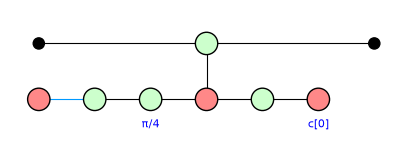

In [2]:
INJECT = """OPENQASM 2.0;
include "qelib1.inc";
qreg q[2];         // q[0] the data, q[1] the magic state
creg c[1];
h q[1]; t q[1];
cx q[0], q[1];
measure q[1] -> c[0];
"""
p = QProgram(2, bits=1, initial_states={1: '0'})
p.add_circuit(Circuit.from_qasm(INJECT), name='inject')
print(INJECT)
draw_program(p, time_axis=False, show_time=False, even_rows=True, figsize=(5, 1.6))

## 2. Question 1: the codes

`logical_action()` with no arguments takes the whole program as the block. Before it, qubit 0 is a free input: the one-qubit code with no stabilizers, $\bar X = X$, $\bar Z = Z$. After it, qubit 1 has been measured, and qubit 0 is again in the one-qubit code with no stabilizers; the tool notes that it holds a non-Clifford logical state, the $T$. With no stabilizers the encoders $E_\mathrm{in}$ and $E_\mathrm{out}$ are plain wires, and the logical action $L$ is the map on qubit 0.

In [3]:
action = p.logical_action()
print("C_in:", action.code_in)
print("C_out:", action.code_out)

C_in: [[1, 1, 1]] CSS code on qubits 0
    logical X X   logical Z Z
C_out: [[1, 1, 1]] CSS code on qubits 0 (holding a non-Clifford logical state)
    logical X X   logical Z Z


## 3. Step 1: the composite

The block between two plain wires is the circuit itself, with the result `c[0]` as a Boolean variable.

step 1, the composite: 13 vertices


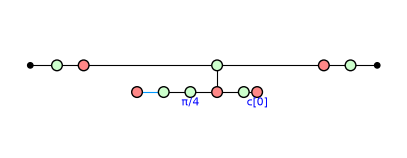

In [4]:
print("step 1, the composite:", action.composite.num_vertices(), "vertices")
draw_graph(action.composite, time_axis=False, show_time=False, figsize=(5, 1.8))

## 4. Step 2: reduce

`reduce_gpf`, with the stages that `to_gpf_steps` records. The result: the data wire (the input on a green spider, a red spider on the output) and a phase gadget on it, a red hub with phase `c[0]`$\pi$ joined to the green spider, and a green leaf $\pi/4$. The gadget multiplies the data's $|1\rangle$ by $e^{i\pi/4}$, and a hub phase of $\pi$ flips its sign, to $e^{-i\pi/4}$. No detectors: the result is random.

step 2: 13 -> 6 -> 5 -> 5 -> 5 -> 6 vertices; detectors: []


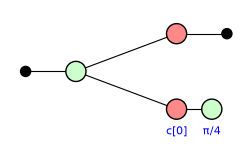

In [5]:
print("step 2:", " -> ".join(str(g.num_vertices()) for _w, g in to_gpf_steps(action.composite.copy())), "vertices;",
      "detectors:", list(action.detectors))
zx.draw_matplotlib(action.result.to_graph(), figsize=(3, 1.6))

## 5. Step 3: the classes of runs

One phase depends on the result, the hub's, so there are two classes, $c = 0$ and $c = 1$, each with one run. For each, the tool puts the run into the reduced diagram and evaluates its $2 \times 2$ matrix, here scaled so that the first entry is 1: $m_0 = \mathrm{diag}(1, e^{i\pi/4})$ and $m_1 = \mathrm{diag}(1, e^{-i\pi/4})$. Trying the Paulis lightest first, $P = I$ already matches: $G = T$ for $c = 0$ and $G = T^\dagger$ for $c = 1$.

In [6]:
matrices = {}
for b in action.branches():
    m = action.matrix(b.outcomes)
    matrices[b.outcomes['c[0]']] = m / m[0, 0]
    print("step 3: {}: matrix diag({})  G = {}, P = {}".format(b.when(), ", ".join(
        "{:.3g}{:+.3g}i".format(z.real + 0.0, z.imag + 0.0) for z in np.round(np.diag(m / m[0, 0]), 3)),
        b.operation, b.correction or 'none'))

step 3: when c[0] = 0: matrix diag(1+0i, 0.707+0.707i)  G = T, P = none
step 3: when c[0] = 1: matrix diag(1+0i, 0.707-0.707i)  G = T^dag, P = none


## 6. Step 4: the check

The codes have no stabilizers, so the block keeps them, and $L$ is what the block does to the data.

In [7]:
print("step 4: stays in the code:", action.stays_in_code())

step 4: stays in the code: True


## 7. Question 3: a Pauli that relates the classes?

The tool looks for a Pauli $Q$ on the output with $m_1 \propto Q\,m_0$, trying $I$, $X$, $Y$, $Z$. Below, the same search by hand: $Q\,m_0$ against $m_1$, up to a factor. $m_1 m_0^{-1} = \mathrm{diag}(1, -i) = S^\dagger$ is diagonal but not a multiple of $I$ or $Z = \mathrm{diag}(1, -1)$, and $X$ and $Y$ are not diagonal: no $Q$. The classes differ by more than a Pauli, and the verdict is *not deterministic*, with each class's operation and condition, as worked out by hand in section 1.

In [8]:
paulis = {'I': np.eye(2), 'X': np.array([[0, 1], [1, 0]]), 'Y': np.array([[0, -1j], [1j, 0]]), 'Z': np.diag([1, -1])}
for name, Q in paulis.items():
    candidate = Q @ matrices[0]
    k = np.unravel_index(np.argmax(np.abs(candidate)), candidate.shape)
    print("Q = {}: m1 is a multiple of Q m0: {}".format(name, np.allclose(matrices[1], matrices[1][k] / candidate[k] * candidate)))
print("Q3: m1 m0^-1 = diag({})".format(", ".join(
    "{:.3g}{:+.3g}i".format(z.real + 0.0, z.imag + 0.0) for z in np.round(np.diag(matrices[1] @ np.linalg.inv(matrices[0])), 3))))
print("Q3:", action.verdict())
print("deterministic:", action.is_deterministic())

Q = I: m1 is a multiple of Q m0: False
Q = X: m1 is a multiple of Q m0: False
Q = Y: m1 is a multiple of Q m0: False
Q = Z: m1 is a multiple of Q m0: False
Q3: m1 m0^-1 = diag(1+0i, 0-1i)
Q3: not deterministic: the operation depends on the outcomes (T when c[0] = 0; T^dag when c[0] = 1)
deterministic: False


## 8. With the correction

The correction is a second stage, the OpenQASM line `if(c==1) s q[0];`. The tool writes it into the diagram as a spider $\pi/4$ on the data wire and a phase gadget with leaf $-\pi/4$ whose hub carries `c[0]` (as zxqec's `ParityControlled('S', 0, ['c[0]'])` does): when $c = 0$ the two cancel, when $c = 1$ they add up to $\pi/2$, an $S$. After the reduction the hub of the $T$'s gadget has phase 0, so no phase depends on the result: one class, $G = T$, *deterministic*.

corrected, step 3: [('in every run', 'T')]
corrected, Q3: deterministic: every run implements T


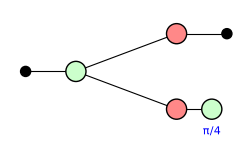

In [9]:
CORRECTION = """OPENQASM 2.0;
include "qelib1.inc";
qreg q[2];
creg c[1];
if(c==1) s q[0];
"""
q = QProgram(2, bits=1, initial_states={1: '0'})
q.add_circuit(Circuit.from_qasm(INJECT), name='inject')
q.add_circuit(Circuit.from_qasm(CORRECTION), name='correct')
corrected = q.logical_action()
print("corrected, step 3:", [(b.when(), b.operation) for b in corrected.branches()])
print("corrected, Q3:", corrected.verdict())
zx.draw_matplotlib(corrected.result.to_graph(), figsize=(3, 1.6))

## Summary

| | without the correction | with `if(c==1) s q[0];` |
|---|---|---|
| by hand | $T$ when $c = 0$, $T^\dagger$ when $c = 1$ | $T$ |
| Question 1 | one qubit, no stabilizers | the same |
| step 2 | data wire + gadget $\pi/4$, hub `c[0]` | data wire + gadget $\pi/4$, hub 0 |
| step 3 | 2 classes: $T$, $T^\dagger$ | 1 class: $T$ |
| Question 3 | no Pauli $Q$ ($m_1 m_0^{-1} = S^\dagger$): not deterministic | deterministic: $T$ |